<a href="https://colab.research.google.com/github/RafaXzaviero/TUGAS-AKHIR/blob/main/TA_Fairness_FaceNet_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluasi Fairness & Bias FaceNet pada Tokoh Publik Indonesia
Notebook ini menjalankan seluruh pipeline: **crop → anotasi → pairs → embedding → evaluasi fairness**.

**Sebelum mulai:** `Runtime > Change runtime type > T4 GPU` (embedding jadi jauh lebih cepat).
Semua file kerja disimpan ke Google Drive supaya aman kalau sesi Colab terputus.

## 0. Instalasi

In [ ]:
!pip -q install deepface tf-keras mtcnn scikit-image scipy tqdm kagglehub
# Jika setelah install muncul peringatan restart: Runtime > Restart session, lalu lanjut dari cell berikutnya.

## 1. Mount Google Drive & folder kerja

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
WORK = "/content/drive/MyDrive/TA_Fairness_FaceNet"
os.makedirs(WORK, exist_ok=True)
%cd {WORK}
print("Folder kerja:", WORK)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/TA_Fairness_FaceNet
Folder kerja: /content/drive/MyDrive/TA_Fairness_FaceNet


## 2. Tulis skrip pipeline (`fairness_pipeline.py`)

In [ ]:
%%writefile fairness_pipeline.py
"""
Pipeline Evaluasi Fairness & Bias FaceNet pada Tokoh Publik Indonesia
=====================================================================
Tahapan (jalankan berurutan):

  1) crop     : deteksi + crop wajah, hitung ITA (estimasi objektif warna kulit)
  2) template : buat file anotasi (skin tone per identitas, pencahayaan per gambar)
  3) pairs    : bangun pasangan genuine & impostor terstratifikasi
  4) embed    : ekstrak embedding FaceNet via DeepFace
  5) evaluate : hitung FAR/FRR per kelompok, CI bootstrap, uji signifikansi, grafik

Contoh:
  python fairness_pipeline.py crop     --src data/raw --dst data/crops --out data/meta_crops.csv
  python fairness_pipeline.py template --meta data/meta_crops.csv --outdir data
  # --> isi kolom 'fitzpatrick' di identities_annot.csv dan 'lighting' di images_annot.csv
  python fairness_pipeline.py pairs    --meta data/meta_crops.csv --id-annot data/identities_annot.csv \
                                       --img-annot data/images_annot.csv --out data/pairs.csv
  python fairness_pipeline.py embed    --pairs data/pairs.csv --model Facenet512 --out data/emb_facenet512.pkl
  python fairness_pipeline.py evaluate --pairs data/pairs.csv --emb data/emb_facenet512.pkl \
                                       --model Facenet512 --outdir results

Asumsi struktur dataset: <src>/<nama_identitas>/<gambar>.jpg
(sesuaikan fungsi `identity_from_path` jika struktur dataset Kaggle berbeda).
"""
import argparse
import itertools
import pickle
import random
from pathlib import Path

import numpy as np
import pandas as pd

IMG_EXT = {".jpg", ".jpeg", ".png", ".webp"}
# Threshold default DeepFace (cosine distance) -> dipakai sebagai threshold "vendor"
DEEPFACE_THR = {"Facenet": 0.40, "Facenet512": 0.30}


def identity_from_path(p: Path) -> str:
    return p.parent.name


# ----------------------------------------------------------------------------
# 1) CROP + ITA
# ----------------------------------------------------------------------------
def compute_ita(face_rgb_uint8: np.ndarray) -> float:
    """Individual Typology Angle dari area pipi (kiri+kanan), dengan pembuangan
    piksel ekstrem (bayangan/highlight) agar lebih robust terhadap pencahayaan."""
    from skimage.color import rgb2lab

    h, w, _ = face_rgb_uint8.shape
    y0, y1 = int(h * 0.50), int(h * 0.75)
    patches = [
        face_rgb_uint8[y0:y1, int(w * 0.15):int(w * 0.35)],
        face_rgb_uint8[y0:y1, int(w * 0.65):int(w * 0.85)],
    ]
    lab = np.concatenate([rgb2lab(p).reshape(-1, 3) for p in patches])
    L, b = lab[:, 0], lab[:, 2]
    lo, hi = np.percentile(L, [10, 90])
    keep = (L >= lo) & (L <= hi)
    L_med, b_med = np.median(L[keep]), np.median(b[keep])
    return float(np.degrees(np.arctan2(L_med - 50.0, b_med)))


def ita_class(ita: float) -> str:
    if ita > 55: return "very_light"
    if ita > 41: return "light"
    if ita > 28: return "intermediate"
    if ita > 10: return "tan"
    if ita > -30: return "brown"
    return "dark"


# Pemetaan kasar ITA -> Fitzpatrick (HANYA untuk analisis sensitivitas / pembanding)
ITA_TO_FITZ = {"intermediate": "III", "tan": "IV", "brown": "V", "dark": "V"}


def cmd_crop(a):
    import cv2
    from deepface import DeepFace
    from tqdm import tqdm

    src, dst = Path(a.src), Path(a.dst)
    files = [p for p in sorted(src.rglob("*")) if p.suffix.lower() in IMG_EXT]
    rows = []
    for p in tqdm(files, desc="crop"):
        ident = identity_from_path(p)
        try:
            faces = DeepFace.extract_faces(
                img_path=str(p), detector_backend=a.detector,
                align=True, enforce_detection=True)
        except Exception:
            rows.append(dict(src_path=str(p), identity=ident, status="no_face"))
            continue
        f = max(faces, key=lambda x: x["facial_area"]["w"] * x["facial_area"]["h"])
        if f.get("confidence", 1.0) < a.min_conf:
            rows.append(dict(src_path=str(p), identity=ident, status="low_conf"))
            continue
        face = f["face"]
        if face.dtype != np.uint8:  # DeepFace baru mengembalikan float 0-1
            face = (np.clip(face, 0, 1) * 255).astype(np.uint8)
        out = dst / ident / f"{p.stem}.jpg"
        out.parent.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(out), cv2.cvtColor(face, cv2.COLOR_RGB2BGR))
        ita = compute_ita(face)
        rows.append(dict(src_path=str(p), path=str(out), identity=ident,
                         n_faces=len(faces), confidence=f.get("confidence", np.nan),
                         ita=ita, ita_class=ita_class(ita), status="ok"))
    df = pd.DataFrame(rows)
    df.to_csv(a.out, index=False)
    print(df["status"].value_counts())
    print(f"Tersimpan: {a.out}")


# ----------------------------------------------------------------------------
# 2) TEMPLATE ANOTASI
# ----------------------------------------------------------------------------
def cmd_template(a):
    meta = pd.read_csv(a.meta)
    meta = meta[meta.status == "ok"]
    ident = (meta.groupby("identity")
             .agg(n_images=("path", "count"), ita_median=("ita", "median"))
             .reset_index())
    ident["ita_class"] = ident.ita_median.apply(ita_class)
    ident["fitzpatrick_ita"] = ident.ita_class.map(ITA_TO_FITZ).fillna("other")
    for k in ("annotator1", "annotator2", "annotator3"):
        ident[k] = ""          # isi III / IV / V oleh tiap anotator
    ident["fitzpatrick"] = ""  # label final (mayoritas / konsensus)
    out = Path(a.outdir)
    out.mkdir(parents=True, exist_ok=True)
    if (out / "identities_annot.csv").exists() and not a.force:
        print("identities_annot.csv sudah ada -> TIDAK ditimpa (pakai --force untuk menimpa).")
        return
    ident.to_csv(out / "identities_annot.csv", index=False)

    img = meta[["path", "identity"]].copy()
    img["lighting"] = ""  # isi: indoor / outdoor
    img.to_csv(out / "images_annot.csv", index=False)
    print("Template dibuat di", out)
    print("Isi: identities_annot.csv (annotator1-3 -> fitzpatrick) & images_annot.csv (lighting)")


# ----------------------------------------------------------------------------
# 3) PAIRS
# ----------------------------------------------------------------------------
def cmd_pairs(a):
    random.seed(a.seed)
    meta = pd.read_csv(a.meta)
    meta = meta[meta.status == "ok"]
    ida = pd.read_csv(a.id_annot)
    ida = ida[ida[a.skin_col].isin(["III", "IV", "V"])][["identity", a.skin_col]]
    ida = ida.rename(columns={a.skin_col: "skin_group"})
    if ida.empty:
        raise SystemExit("Tidak ada identitas berlabel III/IV/V di kolom '%s'. "
                         "Jalankan cell konsensus (6b) / cek file anotasi." % a.skin_col)
    df = meta.merge(ida, on="identity")
    if a.img_annot:
        im = pd.read_csv(a.img_annot)[["path", "lighting"]]
        df = df.merge(im, on="path", how="left")
    else:
        df["lighting"] = np.nan
    if df["lighting"].isna().all():
        print("PERINGATAN: kolom lighting kosong semua -> analisis indoor/outdoor tidak akan valid.")
    df["lighting"] = (df["lighting"].astype("string").str.strip().str.lower()
                      .fillna("unknown").replace("", "unknown"))

    def light_pair(l1, l2):
        if "unknown" in (l1, l2): return "unknown"
        return l1 if l1 == l2 else "mixed"

    rows = []
    for g, dg in df.groupby("skin_group"):
        # genuine
        gen = []
        for ident, di in dg.groupby("identity"):
            combos = list(itertools.combinations(di.index, 2))
            random.shuffle(combos)
            gen += combos[: a.max_genuine_per_id]
        # impostor (dalam kelompok skin tone yang sama)
        idx = list(dg.index)
        n_imp = int(len(gen) * a.impostor_ratio)
        imp, seen, tries = [], set(), 0
        while len(imp) < n_imp and tries < n_imp * 50:
            tries += 1
            i, j = random.sample(idx, 2)
            if dg.at[i, "identity"] == dg.at[j, "identity"]:
                continue
            key = tuple(sorted((i, j)))
            if key in seen:
                continue
            seen.add(key)
            imp.append(key)
        for label, lst in ((1, gen), (0, imp)):
            for i, j in lst:
                rows.append(dict(
                    img1=df.at[i, "path"], img2=df.at[j, "path"], label=label,
                    id1=df.at[i, "identity"], id2=df.at[j, "identity"],
                    skin_group=g,
                    lighting_pair=light_pair(df.at[i, "lighting"], df.at[j, "lighting"])))
    out = pd.DataFrame(rows)
    out.to_csv(a.out, index=False)
    print(out.groupby(["skin_group", "label"]).size().unstack(fill_value=0))
    print(out.groupby(["lighting_pair", "label"]).size().unstack(fill_value=0))


# ----------------------------------------------------------------------------
# 4) EMBEDDING
# ----------------------------------------------------------------------------
def cmd_embed(a):
    from deepface import DeepFace
    from tqdm import tqdm

    pairs = pd.read_csv(a.pairs)
    paths = sorted(set(pairs.img1) | set(pairs.img2))
    emb = {}
    for p in tqdm(paths, desc=f"embed {a.model}"):
        r = DeepFace.represent(img_path=p, model_name=a.model,
                               detector_backend="skip",  # sudah di-crop
                               enforce_detection=False, align=False)
        emb[p] = np.asarray(r[0]["embedding"], dtype=np.float32)
    with open(a.out, "wb") as f:
        pickle.dump(emb, f)
    print(f"{len(emb)} embedding tersimpan di {a.out}")


# ----------------------------------------------------------------------------
# 5) EVALUASI FAIRNESS
# ----------------------------------------------------------------------------
def cos_dist(a, b):
    return 1.0 - float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))


def rates(d, thr):
    gen, imp = d[d.label == 1].dist.values, d[d.label == 0].dist.values
    frr = (gen > thr).mean() if len(gen) else np.nan   # genuine ditolak
    far = (imp <= thr).mean() if len(imp) else np.nan  # impostor diterima
    return far, frr, len(imp), len(gen)


def eer_threshold(d):
    ts = np.unique(np.quantile(d.dist.values, np.linspace(0, 1, 2000)))
    best = min(ts, key=lambda t: abs(np.nan_to_num(rates(d, t)[0]) - np.nan_to_num(rates(d, t)[1])))
    far, frr, *_ = rates(d, best)
    return float(best), float((far + frr) / 2)


def boot_ci(d, thr, n, seed=42):
    rng = np.random.default_rng(seed)
    g, i = d[d.label == 1].dist.values, d[d.label == 0].dist.values
    far_s, frr_s = [], []
    for _ in range(n):
        if len(i): far_s.append((rng.choice(i, len(i)) <= thr).mean())
        if len(g): frr_s.append((rng.choice(g, len(g)) > thr).mean())
    f = lambda x: tuple(np.percentile(x, [2.5, 97.5])) if x else (np.nan, np.nan)
    return f(far_s), f(frr_s)


def group_table(df, col, thr, n_boot):
    rows = []
    for k, d in df.groupby(col):
        far, frr, ni, ng = rates(d, thr)
        (fl, fh), (rl, rh) = boot_ci(d, thr, n_boot)
        rows.append({col: k, "n_genuine": ng, "n_impostor": ni,
                     "FAR": far, "FAR_lo": fl, "FAR_hi": fh,
                     "FRR": frr, "FRR_lo": rl, "FRR_hi": rh})
    return pd.DataFrame(rows)


def fairness_summary(tab):
    def ratio(x):
        x = x.dropna()
        if not len(x) or x.max() == 0:
            return np.nan
        return np.inf if x.min() == 0 else x.max() / x.min()
    return {
        "FAR_gap": tab.FAR.max() - tab.FAR.min(), "FAR_ratio(SER)": ratio(tab.FAR),
        "FRR_gap": tab.FRR.max() - tab.FRR.min(), "FRR_ratio(SER)": ratio(tab.FRR),
    }


def pairwise_tests(df, col, thr):
    """Fisher exact antar pasangan kelompok + koreksi Bonferroni."""
    from scipy.stats import fisher_exact
    groups = sorted(df[col].unique())
    pairs = list(itertools.combinations(groups, 2))
    rows = []
    for g1, g2 in pairs:
        d1, d2 = df[df[col] == g1], df[df[col] == g2]
        for metric in ("FAR", "FRR"):
            def counts(d):
                if metric == "FAR":
                    s = d[d.label == 0].dist.values
                    e = int((s <= thr).sum())
                else:
                    s = d[d.label == 1].dist.values
                    e = int((s > thr).sum())
                return e, len(s) - e
            t = [list(counts(d1)), list(counts(d2))]
            _, p = fisher_exact(t)
            rows.append({"metric": metric, "group1": g1, "group2": g2,
                         "p_value": p, "p_bonferroni": min(1.0, p * len(pairs))})
    return pd.DataFrame(rows)


def cmd_evaluate(a):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    out = Path(a.outdir)
    out.mkdir(parents=True, exist_ok=True)
    pairs = pd.read_csv(a.pairs)
    with open(a.emb, "rb") as f:
        emb = pickle.load(f)
    pairs["dist"] = [cos_dist(emb[x], emb[y]) for x, y in zip(pairs.img1, pairs.img2)]
    pairs["skin_x_light"] = pairs.skin_group + "|" + pairs.lighting_pair
    pairs.to_csv(out / "pairs_with_distance.csv", index=False)

    # --- threshold global (SATU threshold untuk semua kelompok = skenario deployment nyata)
    eer_thr, eer = eer_threshold(pairs)
    imp_all = pairs[pairs.label == 0].dist.values
    thresholds = {
        "deepface_default": DEEPFACE_THR.get(a.model, 0.40),
        "global_EER": eer_thr,
        "global_FAR1pct": float(np.quantile(imp_all, 0.01)),
        "global_FAR0.1pct": float(np.quantile(imp_all, 0.001)),
    }
    print(f"Overall EER = {eer:.4f} @ thr {eer_thr:.4f}")

    summary_rows = []
    for tname, thr in thresholds.items():
        for col in ("skin_group", "lighting_pair", "skin_x_light"):
            d = pairs if col != "lighting_pair" else pairs[pairs.lighting_pair != "unknown"]
            if col == "skin_x_light":
                d = pairs[pairs.lighting_pair != "unknown"]
            if d.empty:
                continue
            tab = group_table(d, col, thr, a.n_boot)
            tab.to_csv(out / f"metrics_{col}_{tname}.csv", index=False)
            s = fairness_summary(tab)
            s.update(threshold_name=tname, threshold=thr, grouping=col)
            summary_rows.append(s)
            if col in ("skin_group", "lighting_pair") and d[col].nunique() > 1:
                pairwise_tests(d, col, thr).to_csv(out / f"tests_{col}_{tname}.csv", index=False)
            print(f"\n== {col} | {tname} (thr={thr:.4f}) ==")
            print(tab.round(4).to_string(index=False))
    pd.DataFrame(summary_rows).to_csv(out / "fairness_summary.csv", index=False)

    # --- Grafik 1: ROC (TAR vs FAR) per kelompok skin tone
    fig, ax = plt.subplots(figsize=(6, 5))
    grid = np.unique(np.quantile(pairs.dist.values, np.linspace(0, 1, 800)))
    for g, d in pairs.groupby("skin_group"):
        far = [rates(d, t)[0] for t in grid]
        tar = [1 - rates(d, t)[1] for t in grid]
        ax.plot(far, tar, label=f"Fitzpatrick {g}")
    ax.set_xscale("log"); ax.set_xlim(1e-3, 1)
    ax.set_xlabel("FAR"); ax.set_ylabel("TAR (1 - FRR)")
    ax.set_title(f"ROC per kelompok skin tone ({a.model})")
    ax.legend(); ax.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(out / "roc_skin_group.png", dpi=200); plt.close(fig)

    # --- Grafik 2: bar FAR/FRR per skin tone pada threshold global_FAR1pct
    tab = group_table(pairs, "skin_group", thresholds["global_FAR1pct"], a.n_boot)
    fig, axs = plt.subplots(1, 2, figsize=(9, 4))
    for ax, m in zip(axs, ("FAR", "FRR")):
        yerr = [tab[m] - tab[f"{m}_lo"], tab[f"{m}_hi"] - tab[m]]
        ax.bar(tab.skin_group, tab[m], yerr=yerr, capsize=4)
        ax.set_title(f"{m} @ threshold FAR global 1%"); ax.set_xlabel("Fitzpatrick")
    fig.tight_layout(); fig.savefig(out / "bar_far_frr.png", dpi=200); plt.close(fig)

    # --- Grafik 3: distribusi jarak genuine vs impostor per kelompok
    groups = sorted(pairs.skin_group.unique())
    fig, axs = plt.subplots(1, len(groups), figsize=(4 * len(groups), 3.5), sharey=True)
    axs = np.atleast_1d(axs)
    for ax, g in zip(axs, groups):
        d = pairs[pairs.skin_group == g]
        ax.hist(d[d.label == 1].dist, bins=40, alpha=.6, density=True, label="genuine")
        ax.hist(d[d.label == 0].dist, bins=40, alpha=.6, density=True, label="impostor")
        ax.axvline(thresholds["global_FAR1pct"], ls="--", c="k")
        ax.set_title(f"Fitzpatrick {g}"); ax.set_xlabel("cosine distance")
    axs[0].legend()
    fig.tight_layout(); fig.savefig(out / "dist_hist.png", dpi=200); plt.close(fig)
    print(f"\nSemua hasil tersimpan di {out}/")


# ----------------------------------------------------------------------------
def main():
    ap = argparse.ArgumentParser()
    sp = ap.add_subparsers(dest="cmd", required=True)

    c = sp.add_parser("crop")
    c.add_argument("--src", required=True); c.add_argument("--dst", required=True)
    c.add_argument("--out", required=True)
    c.add_argument("--detector", default="mtcnn")
    c.add_argument("--min-conf", type=float, default=0.90)
    c.set_defaults(f=cmd_crop)

    t = sp.add_parser("template")
    t.add_argument("--meta", required=True); t.add_argument("--outdir", required=True)
    t.add_argument("--force", action="store_true", help="timpa template yang sudah ada")
    t.set_defaults(f=cmd_template)

    p = sp.add_parser("pairs")
    p.add_argument("--meta", required=True); p.add_argument("--id-annot", required=True)
    p.add_argument("--img-annot"); p.add_argument("--out", required=True)
    p.add_argument("--skin-col", default="fitzpatrick",
                   help="'fitzpatrick' (anotasi manual) atau 'fitzpatrick_ita' (sensitivitas)")
    p.add_argument("--max-genuine-per-id", type=int, default=30)
    p.add_argument("--impostor-ratio", type=float, default=1.0)
    p.add_argument("--seed", type=int, default=42)
    p.set_defaults(f=cmd_pairs)

    e = sp.add_parser("embed")
    e.add_argument("--pairs", required=True); e.add_argument("--out", required=True)
    e.add_argument("--model", default="Facenet512", choices=["Facenet", "Facenet512"])
    e.set_defaults(f=cmd_embed)

    v = sp.add_parser("evaluate")
    v.add_argument("--pairs", required=True); v.add_argument("--emb", required=True)
    v.add_argument("--model", default="Facenet512"); v.add_argument("--outdir", default="results")
    v.add_argument("--n-boot", type=int, default=1000)
    v.set_defaults(f=cmd_evaluate)

    a = ap.parse_args()
    a.f(a)


if __name__ == "__main__":
    main()


Overwriting fairness_pipeline.py


## 3. Unduh dataset Kaggle
Dataset: `arifnuriman/indonesian-public-figure-faces`.
Opsi A (`kagglehub`) biasanya langsung jalan untuk dataset publik. Jika error autentikasi, pakai Opsi B (upload `kaggle.json`).

In [ ]:
# --- Opsi A: kagglehub
import kagglehub
DATA_DIR = kagglehub.dataset_download("arifnuriman/indonesian-public-figure-faces")
print("Dataset di:", DATA_DIR)

Using Colab cache for faster access to the 'indonesian-public-figure-faces' dataset.
Dataset di: /kaggle/input/indonesian-public-figure-faces


In [ ]:
# --- Opsi B (jalankan HANYA jika Opsi A gagal): upload kaggle.json dari akun Kaggle > Settings > Create New Token
# from google.colab import files
# files.upload()
# !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d arifnuriman/indonesian-public-figure-faces -p /content/raw --unzip
# DATA_DIR = "/content/raw"

### Cek struktur dataset
Skrip mengasumsikan `DATA_DIR/<nama_identitas>/<gambar>.jpg`. Pastikan nama folder = identitas.
Kalau ada level folder tambahan (mis. `train/<identitas>/...`), arahkan `DATA_DIR` ke folder yang langsung berisi folder identitas.

In [ ]:
import os, collections
for root, dirs, files in os.walk(DATA_DIR):
    depth = root[len(DATA_DIR):].count(os.sep)
    if depth <= 1:
        print("  " * depth + os.path.basename(root) + f"/  ({len(files)} file, {len(dirs)} subfolder)")
    if depth >= 2: break

indonesian-public-figure-faces/  (0 file, 1 subfolder)
  Extracted/  (0 file, 99 subfolder)


In [ ]:
# Statistik jumlah gambar per identitas
from pathlib import Path
EXT = {".jpg",".jpeg",".png",".webp"}
cnt = collections.Counter(p.parent.name for p in Path(DATA_DIR).rglob("*") if p.suffix.lower() in EXT)
import pandas as pd
s = pd.Series(cnt)
print("Jumlah identitas:", len(s), "| total gambar:", s.sum())
print(s.describe())
print("Identitas dengan >=2 gambar:", (s>=2).sum())

Jumlah identitas: 99 | total gambar: 640
count    99.000000
mean      6.464646
std       2.026927
min       2.000000
25%       5.000000
50%       7.000000
75%       8.000000
max      11.000000
dtype: float64
Identitas dengan >=2 gambar: 99


## 4. Crop wajah + hitung ITA
Tahap terlama. Hasil tersimpan di Drive (`crops/`, `meta_crops.csv`).

In [ ]:
import os
if os.path.exists("meta_crops.csv"):
    print("meta_crops.csv sudah ada -> crop DILEWATI (hapus file ini jika ingin crop ulang).")
else:
    !python fairness_pipeline.py crop --src "{DATA_DIR}" --dst crops --out meta_crops.csv --detector mtcnn

meta_crops.csv sudah ada -> crop DILEWATI (hapus file ini jika ingin crop ulang).


## 4b. Analisis Eksplorasi Data (Exploratory Data Analysis - EDA)
Sebelum masuk ke pembuatan template anotasi dan pemodelan, mari kita analisis karakteristik dataset hasil cropping dan perhitungan ITA untuk memahami distribusi warna kulit, jumlah wajah terdeteksi, serta statistiknya.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Pastikan kita membaca file meta_crops.csv terbaru
if os.path.exists("meta_crops.csv"):
    df_meta = pd.read_csv("meta_crops.csv")
    print(f"Total data di meta_crops: {len(df_meta)} baris")
    display(df_meta.head())
else:
    print("File meta_crops.csv belum tersedia. Silakan jalankan proses crop terlebih dahulu.")

Total data di meta_crops: 640 baris


,src_path,path,identity,n_faces,confidence,ita,ita_class,status
0,/kaggle/input/indonesian-public-figure-faces/E...,crops/Abdel_Achrian/12.jpg,Abdel_Achrian,1.0,1.0,29.885982,intermediate,ok
1,/kaggle/input/indonesian-public-figure-faces/E...,crops/Abdel_Achrian/15.jpg,Abdel_Achrian,1.0,1.0,82.835352,very_light,ok
2,/kaggle/input/indonesian-public-figure-faces/E...,crops/Abdel_Achrian/6.jpg,Abdel_Achrian,1.0,1.0,11.222370,tan,ok
3,/kaggle/input/indonesian-public-figure-faces/E...,crops/Abdurrahim_Arsyad/10.jpg,Abdurrahim_Arsyad,1.0,1.0,-47.577458,dark,ok
4,/kaggle/input/indonesian-public-figure-faces/E...,crops/Abdurrahim_Arsyad/12.jpg,Abdurrahim_Arsyad,1.0,1.0,67.749124,very_light,ok


Wajah berhasil dideteksi & di-crop: 624 dari 640 gambar (97.5%)


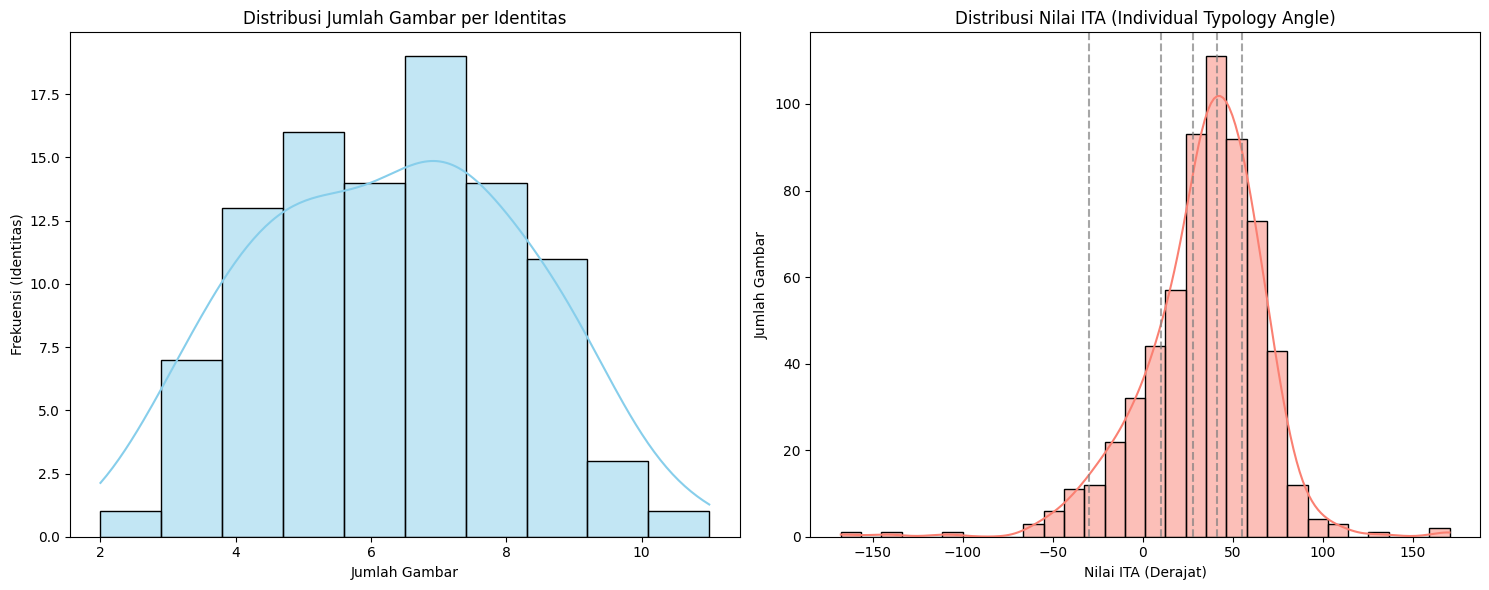

In [ ]:
# Saring data yang sukses di-crop (status == 'ok')
df_ok = df_meta[df_meta['status'] == 'ok'].copy()
print(f"Wajah berhasil dideteksi & di-crop: {len(df_ok)} dari {len(df_meta)} gambar ({len(df_ok)/len(df_meta)*100:.1f}%)")

# Buat visualisasi multi-plot untuk EDA
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Distribusi jumlah gambar per identitas
sns.histplot(df_ok.groupby('identity').size(), bins=10, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribusi Jumlah Gambar per Identitas')
axes[0].set_xlabel('Jumlah Gambar')
axes[0].set_ylabel('Frekuensi (Identitas)')

# 2. Distribusi Nilai ITA (Individual Typology Angle)
sns.histplot(df_ok['ita'], bins=30, kde=True, ax=axes[1], color='salmon')
axes[1].axvline(55, color='gray', linestyle='--', alpha=0.7, label='Very Light (>55)')
axes[1].axvline(41, color='gray', linestyle='--', alpha=0.7, label='Light (>41)')
axes[1].axvline(28, color='gray', linestyle='--', alpha=0.7, label='Intermediate (>28)')
axes[1].axvline(10, color='gray', linestyle='--', alpha=0.7, label='Tan (>10)')
axes[1].axvline(-30, color='gray', linestyle='--', alpha=0.7, label='Brown (>-30)')
axes[1].set_title('Distribusi Nilai ITA (Individual Typology Angle)')
axes[1].set_xlabel('Nilai ITA (Derajat)')
axes[1].set_ylabel('Jumlah Gambar')

plt.tight_layout()
plt.show()

=== Distribusi Kategori Warna Kulit (Estimasi Objektif ITA) ===


,Kategori ITA,Jumlah Gambar,Persentase (%)
0,very_light,156,25.00
1,intermediate,127,20.35
2,light,125,20.03
3,tan,99,15.87
4,brown,94,15.06
5,dark,23,3.69


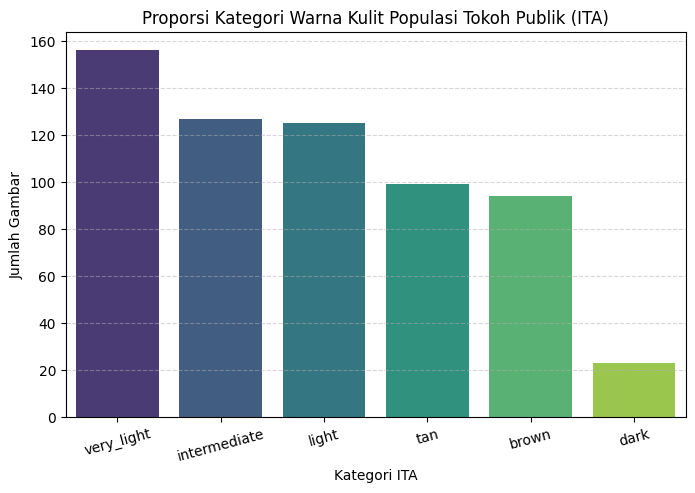

In [ ]:
# Analisis distribusi kategori warna kulit berdasarkan ITA otomatis
ita_dist = df_ok['ita_class'].value_counts().reset_index()
ita_dist.columns = ['Kategori ITA', 'Jumlah Gambar']
ita_dist['Persentase (%)'] = (ita_dist['Jumlah Gambar'] / len(df_ok) * 100).round(2)

print("=== Distribusi Kategori Warna Kulit (Estimasi Objektif ITA) ===")
display(ita_dist)

# Tampilkan diagram batang kategori warna kulit
plt.figure(figsize=(8, 5))
sns.barplot(data=ita_dist, x='Kategori ITA', y='Jumlah Gambar', palette='viridis', hue='Kategori ITA', legend=False)
plt.title('Proporsi Kategori Warna Kulit Populasi Tokoh Publik (ITA)')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

## 5. Buat template anotasi

In [ ]:
!python fairness_pipeline.py template --meta meta_crops.csv --outdir .

identities_annot.csv sudah ada -> TIDAK ditimpa (pakai --force untuk menimpa).


## 6. Anotasi Fitzpatrick (III / IV / V) & pencahayaan (indoor / outdoor)
**Pratinjau gambar** dulu untuk membantu anotasi. Ubah `start` untuk melihat halaman berikutnya.

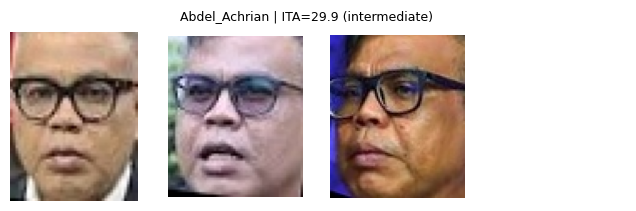

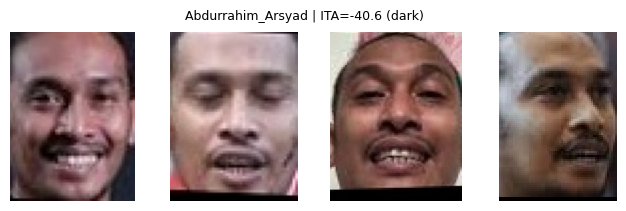

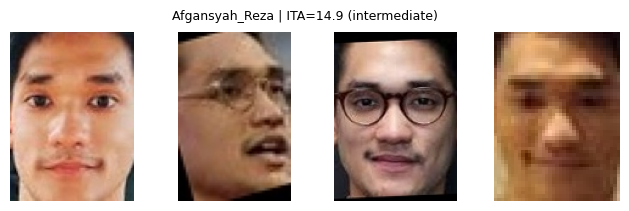

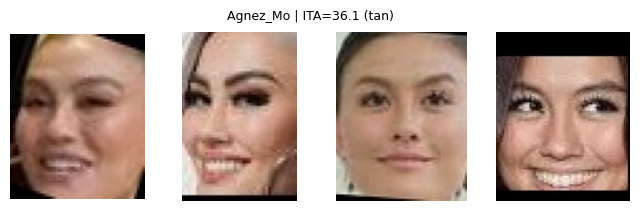

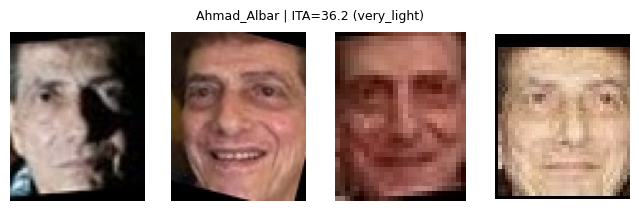

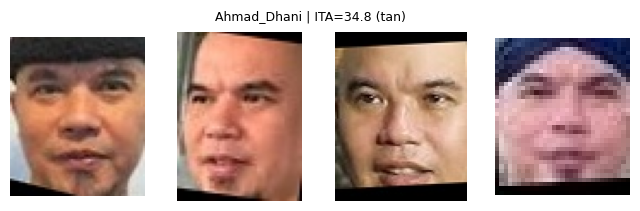

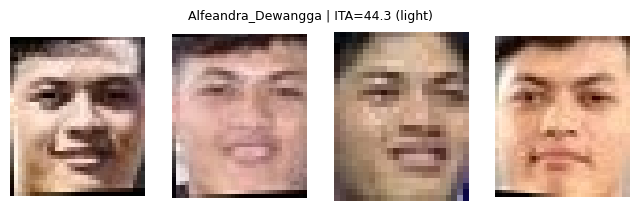

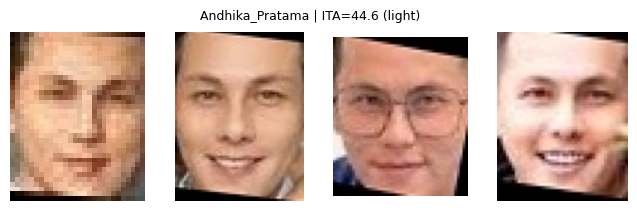

In [ ]:
import numpy as np, cv2, matplotlib.pyplot as plt, pandas as pd
meta = pd.read_csv("meta_crops.csv"); meta = meta[meta.status=="ok"]
ids = sorted(meta.identity.unique())

def show(start=0, n=8, k=4):
    for ident in ids[start:start+n]:
        d = meta[meta.identity==ident].head(k)
        fig, axs = plt.subplots(1, k, figsize=(2*k, 2.2))
        for ax in np.atleast_1d(axs): ax.axis("off")
        for ax, (_, r) in zip(np.atleast_1d(axs), d.iterrows()):
            ax.imshow(cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB))
        fig.suptitle(f"{ident} | ITA={d.ita.median():.1f} ({d.ita_class.iloc[0]})", fontsize=9)
        plt.show()

show(start=0)

**Unduh template → isi di Excel/Google Sheets → unggah kembali.**

- `identities_annot.csv`: isi kolom `annotator1`, `annotator2`, `annotator3` dengan **III / IV / V** (disarankan 2–3 anotator berbeda).
- `images_annot.csv`: isi kolom `lighting` dengan **indoor** atau **outdoor** (per gambar).

Alternatif: karena file ada di Google Drive, kamu juga bisa unduh langsung dari folder Drive dan menimpanya setelah diisi.

In [ ]:
from google.colab import files
files.download("identities_annot.csv")
files.download("images_annot.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Cara memasukkan file berlabel (disarankan):** seret file CSV yang sudah kamu isi ke folder Drive `TA_Fairness_FaceNet` lewat browser, lalu jalankan cell di bawah. Cell ini otomatis memilih file yang **paling banyak terisi** (misalnya `identities_annot (1).csv` atau `..._classified.csv`), membersihkan formatnya (pemisah `;`, BOM), dan menyimpannya ke nama baku `identities_annot.csv` / `images_annot.csv`.

In [ ]:
import glob, pandas as pd

def load_clean(path):
    df = pd.read_csv(path, sep=None, engine="python", encoding="utf-8-sig")
    df.columns = df.columns.str.strip()
    # Jika kolom berubah menjadi Column1, Column2, dst. karena kendala konversi,
    # kita kembalikan ke nama header asli berdasarkan posisinya
    if len(df.columns) >= 9 and list(df.columns)[:3] == ['Column1', 'Column2', 'Column3']:
        print(f"\n[INFO] Mengembalikan kolom generik pada {path} ke header standar.")
        df.columns = ['identity', 'n_images', 'ita_median', 'ita_class', 'fitzpatrick_ita', 'annotator1', 'annotator2', 'annotator3', 'fitzpatrick'] + list(df.columns[9:])
    return df

def pick(pattern, filled_cols):
    best, best_n = None, -1
    for f in glob.glob(pattern):
        try:
            d = load_clean(f)
            # Cetak semua kolom yang ada di file untuk membantu debug
            if "identities_annot" in f:
                print(f"\n[DEBUG] File: {f} -> Kolom aktif: {list(d.columns)}")

            n = sum(d[c].astype(str).str.strip().replace({"nan": ""}).ne("").sum() for c in filled_cols if c in d)
            if "identities_annot" in f:
                cols_found = [c for c in filled_cols if c in d.columns]
                print(f"[DEBUG] Kolom target ditemukan: {cols_found} | Jumlah baris terisi: {n}")
                if cols_found:
                    print("Sampel data baris pertama:\n", d[cols_found].head(3))
        except Exception as e:
            print("lewati", f, e); continue
        if n > best_n: best, best_n = f, n
    return best, best_n

f_id,  n_id  = pick("identities_annot*.csv", ["annotator1", "annotator2", "annotator3"])
f_img, n_img = pick("images_annot*.csv", ["lighting"])
print("\nDipakai:", f_id, "|", f_img)

assert n_id > 0,  "Belum ada file identitas yang berlabel (annotator1-3 kosong semua). Pastikan Anda sudah mengunggah file yang kolom annotator1/2/3 nya terisi III, IV, atau V."
assert n_img > 0, "Belum ada file gambar yang berlabel (lighting kosong semua)."

load_clean(f_id).to_csv("identities_annot.csv", index=False)
load_clean(f_img).to_csv("images_annot.csv", index=False)
print(pd.read_csv("images_annot.csv")["lighting"].value_counts(dropna=False))


[INFO] Mengembalikan kolom generik pada identities_annot.csv ke header standar.

[DEBUG] File: identities_annot.csv -> Kolom aktif: ['identity', 'n_images', 'ita_median', 'ita_class', 'fitzpatrick_ita', 'annotator1', 'annotator2', 'annotator3', 'fitzpatrick']
[DEBUG] Kolom target ditemukan: ['annotator1', 'annotator2', 'annotator3'] | Jumlah baris terisi: 300
Sampel data baris pertama:
           annotator1          annotator2          annotator3
0  annotator1 (arya)  annotator2 (sulak)  annotator3 (tegar)
1                 IV                  IV                  IV
2                  V                   V                   V

[INFO] Mengembalikan kolom generik pada identities_annot1.csv ke header standar.

[DEBUG] File: identities_annot1.csv -> Kolom aktif: ['identity', 'n_images', 'ita_median', 'ita_class', 'fitzpatrick_ita', 'annotator1', 'annotator2', 'annotator3', 'fitzpatrick']
[DEBUG] Kolom target ditemukan: ['annotator1', 'annotator2', 'annotator3'] | Jumlah baris terisi: 300


In [ ]:
import shutil
import os

# Memastikan file disalin ke nama standar agar bisa langsung dieksekusi oleh langkah selanjutnya
for src, dst in [('identities_annot1.csv', 'identities_annot.csv'), ('images_annot1.csv', 'images_annot.csv')]:
    if os.path.exists(src):
        shutil.copy(src, dst)
        print(f"✓ Berhasil menyalin {src} -> {dst}")
    else:
        print(f"⚠️ File {src} tidak ditemukan di folder kerja saat ini. Pastikan Anda berada di direktori Drive yang benar.")


✓ Berhasil menyalin identities_annot1.csv -> identities_annot.csv
✓ Berhasil menyalin images_annot1.csv -> images_annot.csv


### 6b. Agreement antar-anotator (Cohen's kappa) & label konsensus
Hasil kappa dilaporkan di bagian Metode jurnal. Label final `fitzpatrick` = suara mayoritas; yang tidak ada mayoritas ditandai untuk didiskusikan.

In [ ]:
import pandas as pd, itertools
from sklearn.metrics import cohen_kappa_score
ida = pd.read_csv("identities_annot.csv")
ann = [c for c in ["annotator1","annotator2","annotator3"] if ida[c].notna().any() and (ida[c].astype(str).str.strip()!="").any()]
print("Anotator terisi:", ann)

ok = ida.dropna(subset=ann)
for a, b in itertools.combinations(ann, 2):
    print(f"Cohen's kappa {a} vs {b}: {cohen_kappa_score(ok[a], ok[b], weights='linear'):.3f}  (linear-weighted)")

def majority(row):
    vals = [str(row[c]).strip() for c in ann if str(row[c]).strip() in ("III","IV","V")]
    if not vals: return ""
    top = pd.Series(vals).value_counts()
    return top.index[0] if (len(top)==1 or top.iloc[0] > top.iloc[1]) else "TIE"

ida["fitzpatrick"] = ida.apply(majority, axis=1)
print(ida.fitzpatrick.value_counts())
print("Cek & selesaikan baris 'TIE' secara manual jika ada:")
display(ida[ida.fitzpatrick=="TIE"])
ida.to_csv("identities_annot.csv", index=False)

# Agreement antara konsensus manual vs estimasi ITA (analisis sensitivitas)
m = ida[ida.fitzpatrick.isin(["III","IV","V"]) & ida.fitzpatrick_ita.isin(["III","IV","V"])]
print("Kappa konsensus manual vs ITA:", round(cohen_kappa_score(m.fitzpatrick, m.fitzpatrick_ita, weights='linear'),3))

Anotator terisi: ['annotator1', 'annotator2', 'annotator3']
Cohen's kappa annotator1 vs annotator2: 0.986  (linear-weighted)
Cohen's kappa annotator1 vs annotator3: 0.981  (linear-weighted)
Cohen's kappa annotator2 vs annotator3: 0.980  (linear-weighted)
fitzpatrick
III    41
       32
IV     24
V       3
Name: count, dtype: int64
Cek & selesaikan baris 'TIE' secara manual jika ada:


,identity,n_images,ita_median,ita_class,fitzpatrick_ita,annotator1,annotator2,annotator3,fitzpatrick


Kappa konsensus manual vs ITA: 0.622


## 7. Bangun pasangan genuine & impostor

In [ ]:
!python fairness_pipeline.py pairs --meta meta_crops.csv --id-annot identities_annot.csv --img-annot images_annot.csv --out pairs.csv --max-genuine-per-id 30 --impostor-ratio 1.0
# Pastikan tiap kelompok punya cukup pasangan (idealnya ratusan+). Kurangi/naikkan --max-genuine-per-id sesuai data.

label         0    1
skin_group          
III         727  727
IV          276  276
V            61   61
label            0    1
lighting_pair          
indoor         248  276
mixed          523  473
outdoor        293  315


## 8. Ekstrak embedding FaceNet
Jalankan untuk **Facenet (128-d)** dan **Facenet512** supaya bisa dibandingkan di jurnal.

In [ ]:
!python fairness_pipeline.py embed --pairs pairs.csv --model Facenet    --out emb_facenet.pkl
!python fairness_pipeline.py embed --pairs pairs.csv --model Facenet512 --out emb_facenet512.pkl

I0000 00:00:1794316234.850974    6787 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794316238.453884    6787 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
embed Facenet: 100% 403/403 [03:47<00:00,  1.77it/s]
403 embedding tersimpan di emb_facenet.pkl
I0000 00:00:1794316472.241094    7747 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794316478.201746    7747 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
embed Facenet512: 100% 403/403 [03:03<00:00,  2.19it/s]
403 embedding tersimpan di emb_facenet512.pkl


## 9. Evaluasi fairness

In [ ]:
!python fairness_pipeline.py evaluate --pairs pairs.csv --emb emb_facenet.pkl    --model Facenet    --outdir results_facenet
!python fairness_pipeline.py evaluate --pairs pairs.csv --emb emb_facenet512.pkl --model Facenet512 --outdir results_facenet512

Overall EER = 0.1621 @ thr 0.5754

== skin_group | deepface_default (thr=0.4000) ==
skin_group  n_genuine  n_impostor    FAR  FAR_lo  FAR_hi    FRR  FRR_lo  FRR_hi
       III        727         727 0.0234  0.0138  0.0344 0.4594  0.4250  0.4938
        IV        276         276 0.0072  0.0000  0.0181 0.4094  0.3551  0.4674
         V         61          61 0.0328  0.0000  0.0820 0.6230  0.4918  0.7377

== lighting_pair | deepface_default (thr=0.4000) ==
lighting_pair  n_genuine  n_impostor    FAR  FAR_lo  FAR_hi    FRR  FRR_lo  FRR_hi
       indoor        276         248 0.0202  0.0040  0.0403 0.5254  0.4673  0.5870
        mixed        473         523 0.0153  0.0057  0.0268 0.4588  0.4165  0.5011
      outdoor        315         293 0.0273  0.0102  0.0478 0.3905  0.3365  0.4444

== skin_x_light | deepface_default (thr=0.4000) ==
skin_x_light  n_genuine  n_impostor    FAR  FAR_lo  FAR_hi    FRR  FRR_lo  FRR_hi
  III|indoor        157         124 0.0242  0.0000  0.0484 0.4713  0.4011  0.

### Ringkasan & grafik

===== results_facenet


,FAR_gap,FAR_ratio(SER),FRR_gap,FRR_ratio(SER),threshold_name,threshold,grouping
0,0.0255,4.5246,0.2135,1.5215,deepface_default,0.4000,skin_group
1,0.0120,1.7850,0.1349,1.3454,deepface_default,0.4000,lighting_pair
2,0.0400,inf,0.7534,4.0556,deepface_default,0.4000,skin_x_light
3,0.1519,2.1977,0.1993,2.3754,global_EER,0.5754,skin_group
4,0.0279,1.1815,0.0786,1.6519,global_EER,0.5754,lighting_pair
5,0.3235,inf,0.9452,18.2500,global_EER,0.5754,skin_x_light
6,0.0128,4.5246,0.2139,1.4506,global_FAR1pct,0.3708,skin_group
7,0.0167,5.9073,0.1502,1.3356,global_FAR1pct,0.3708,lighting_pair
8,0.0294,inf,0.7260,3.6500,global_FAR1pct,0.3708,skin_x_light
9,0.0028,inf,0.1953,1.2642,global_FAR0.1pct,0.2624,skin_group


,skin_group,n_genuine,n_impostor,FAR,FAR_lo,FAR_hi,FRR,FRR_lo,FRR_hi
0,III,727,727,0.0124,0.0055,0.0206,0.5213,0.4842,0.5571
1,IV,276,276,0.0036,0.0000,0.0109,0.4746,0.4167,0.5326
2,V,61,61,0.0164,0.0000,0.0492,0.6885,0.5574,0.8033


,metric,group1,group2,p_value,p_bonferroni
0,FAR,III,IV,0.3005,0.9015
1,FRR,III,IV,0.2032,0.6095
2,FAR,III,V,0.5554,1.0000
3,FRR,III,V,0.0156,0.0467
4,FAR,IV,V,0.3297,0.9891
5,FRR,IV,V,0.0028,0.0085


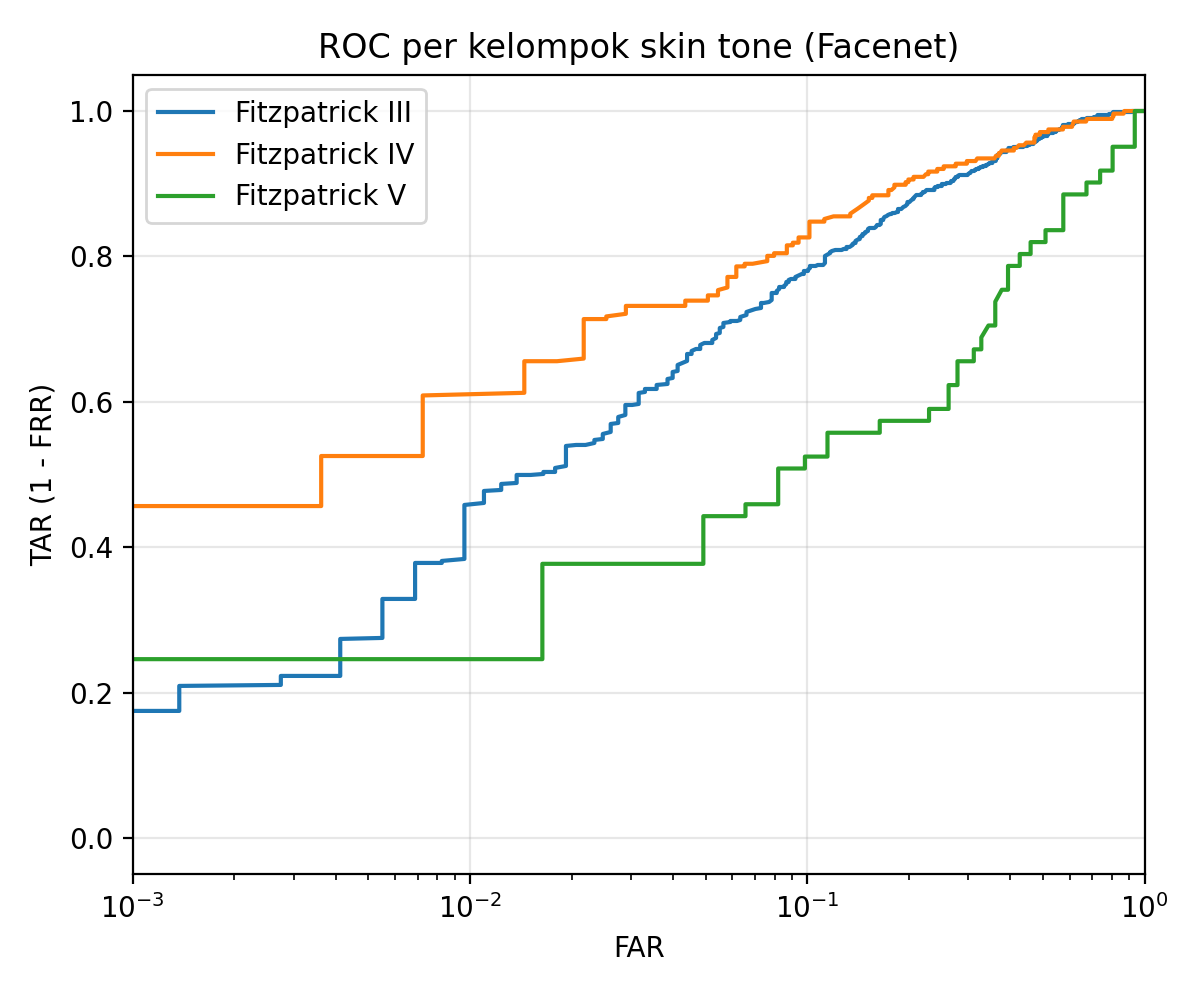

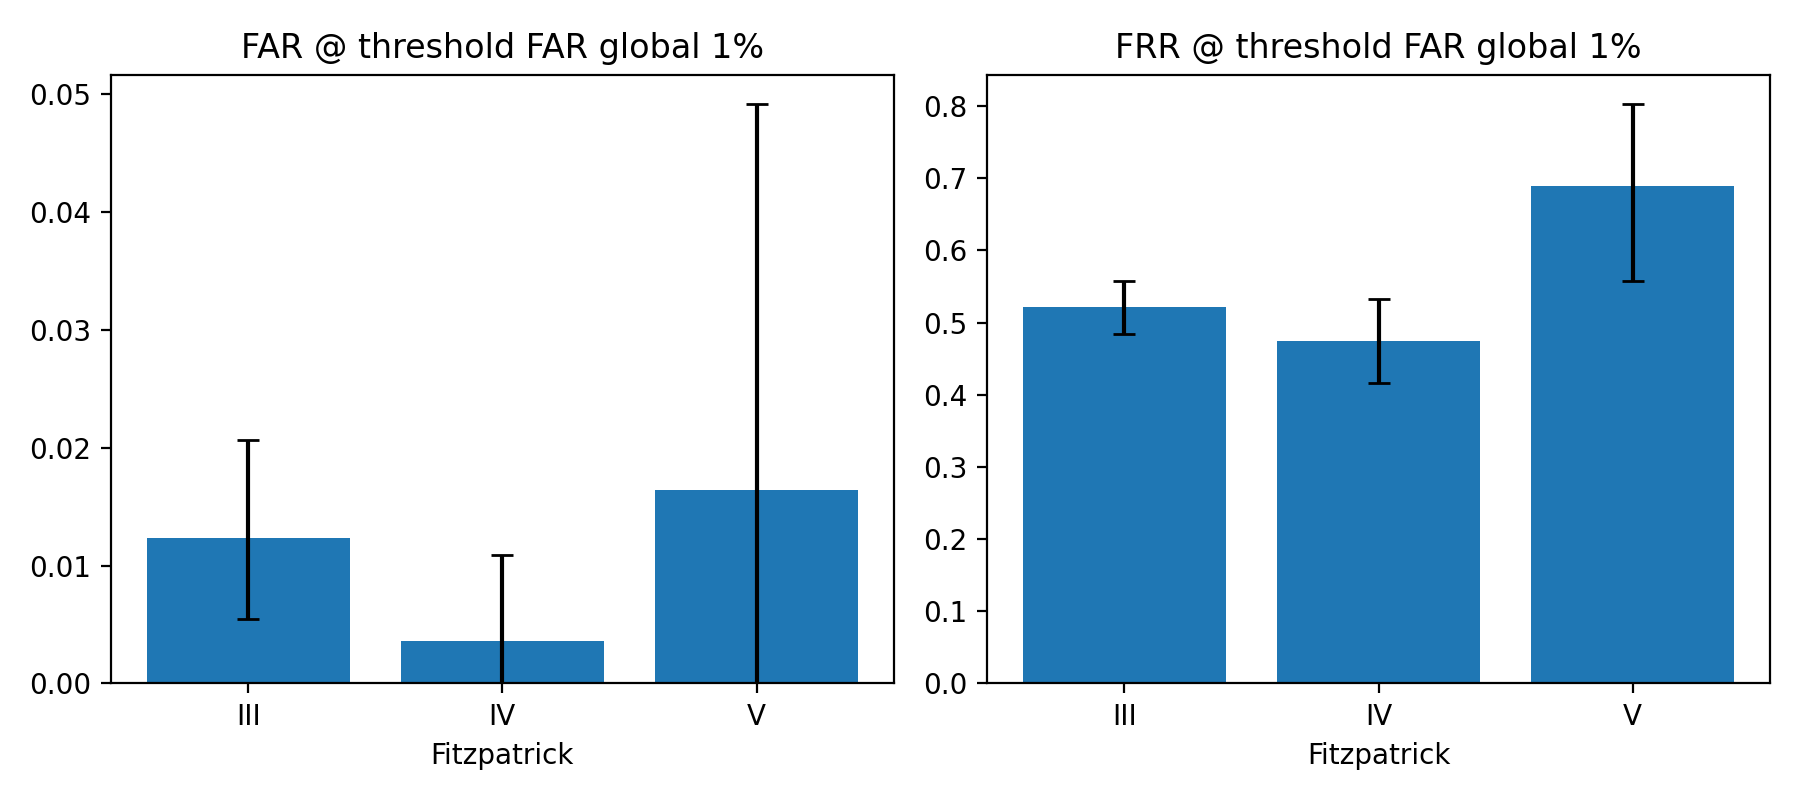

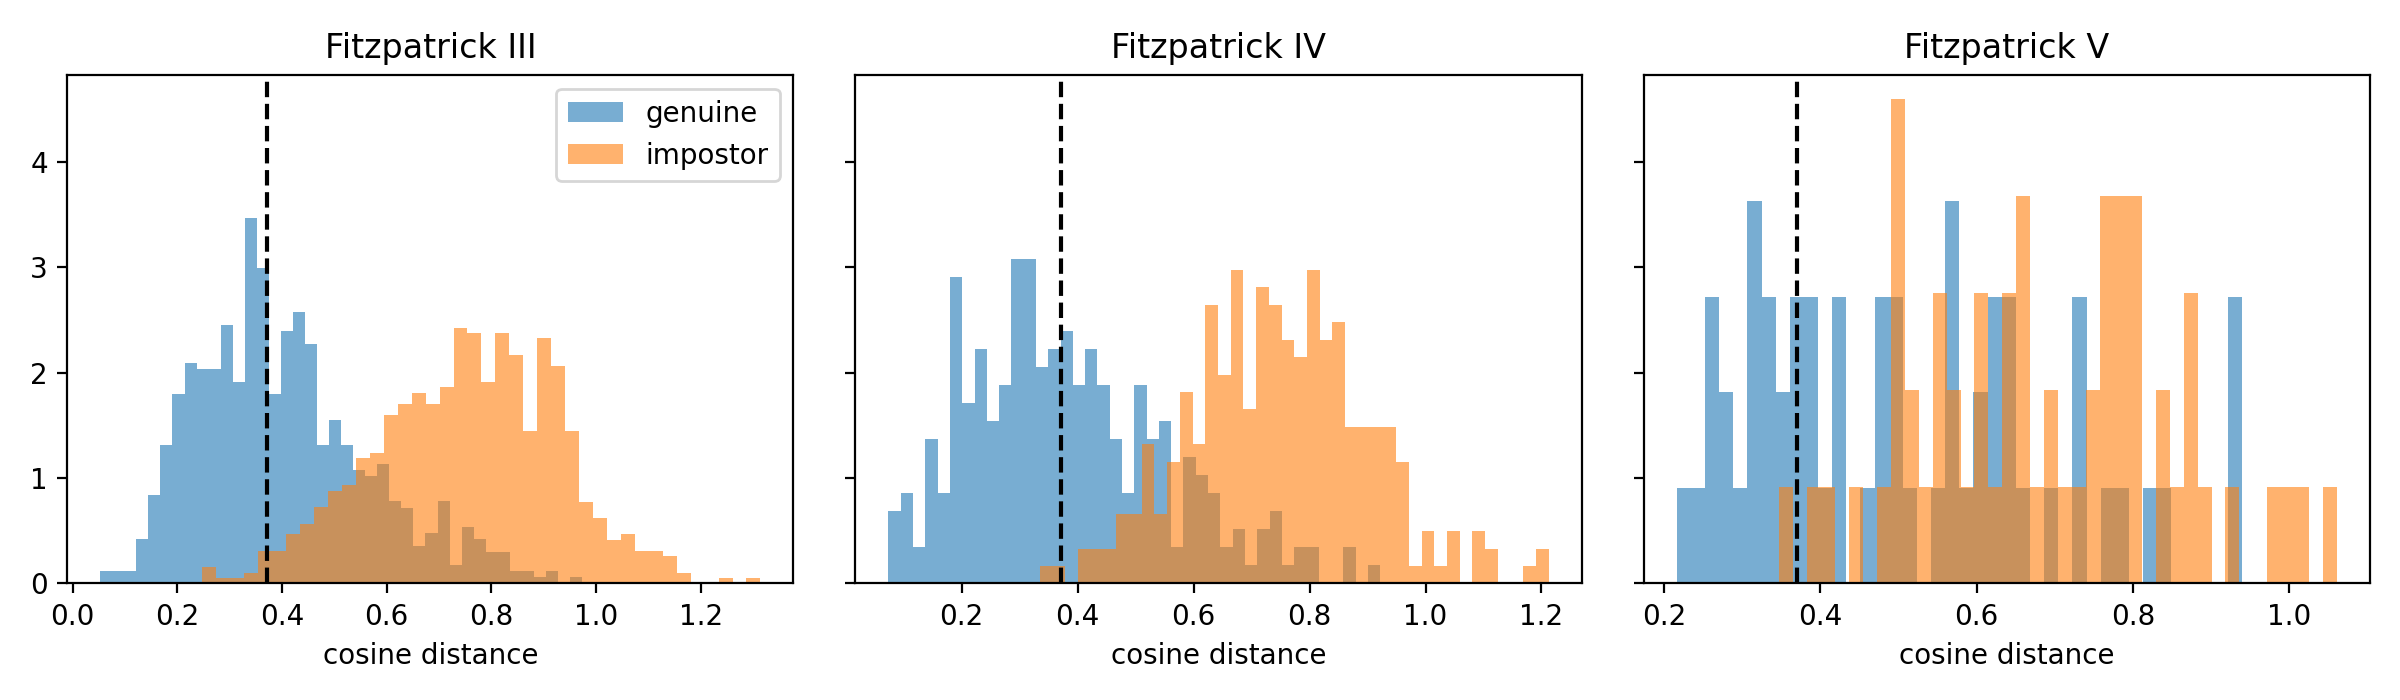

===== results_facenet512


,FAR_gap,FAR_ratio(SER),FRR_gap,FRR_ratio(SER),threshold_name,threshold,grouping
0,0.0164,inf,0.1687,1.3146,deepface_default,0.3000,skin_group
1,0.0081,inf,0.2167,1.4492,deepface_default,0.3000,lighting_pair
2,0.0294,inf,0.6438,2.8077,deepface_default,0.3000,skin_x_light
3,0.2483,3.2110,0.1136,1.9795,global_EER,0.5041,skin_group
4,0.0447,1.3829,0.1167,2.4143,global_EER,0.5041,lighting_pair
5,0.4070,5.3750,0.2400,inf,global_EER,0.5041,skin_x_light
6,0.0068,1.7026,0.2732,1.8197,global_FAR1pct,0.3555,skin_group
7,0.0053,1.7722,0.1780,1.5289,global_FAR1pct,0.3555,lighting_pair
8,0.0294,inf,0.7945,4.8667,global_FAR1pct,0.3555,skin_x_light
9,0.0164,inf,0.2203,1.3397,global_FAR0.1pct,0.2531,skin_group


,skin_group,n_genuine,n_impostor,FAR,FAR_lo,FAR_hi,FRR,FRR_lo,FRR_hi
0,III,727,727,0.0096,0.0041,0.0179,0.4347,0.3989,0.4704
1,IV,276,276,0.0109,0.0000,0.0254,0.3333,0.2790,0.3877
2,V,61,61,0.0164,0.0000,0.0496,0.6066,0.4754,0.7217


,metric,group1,group2,p_value,p_bonferroni
0,FAR,III,IV,1.0000,1.0000
1,FRR,III,IV,0.0040,0.0119
2,FAR,III,V,0.4767,1.0000
3,FRR,III,V,0.0108,0.0323
4,FAR,IV,V,0.5519,1.0000
5,FRR,IV,V,0.0001,0.0004


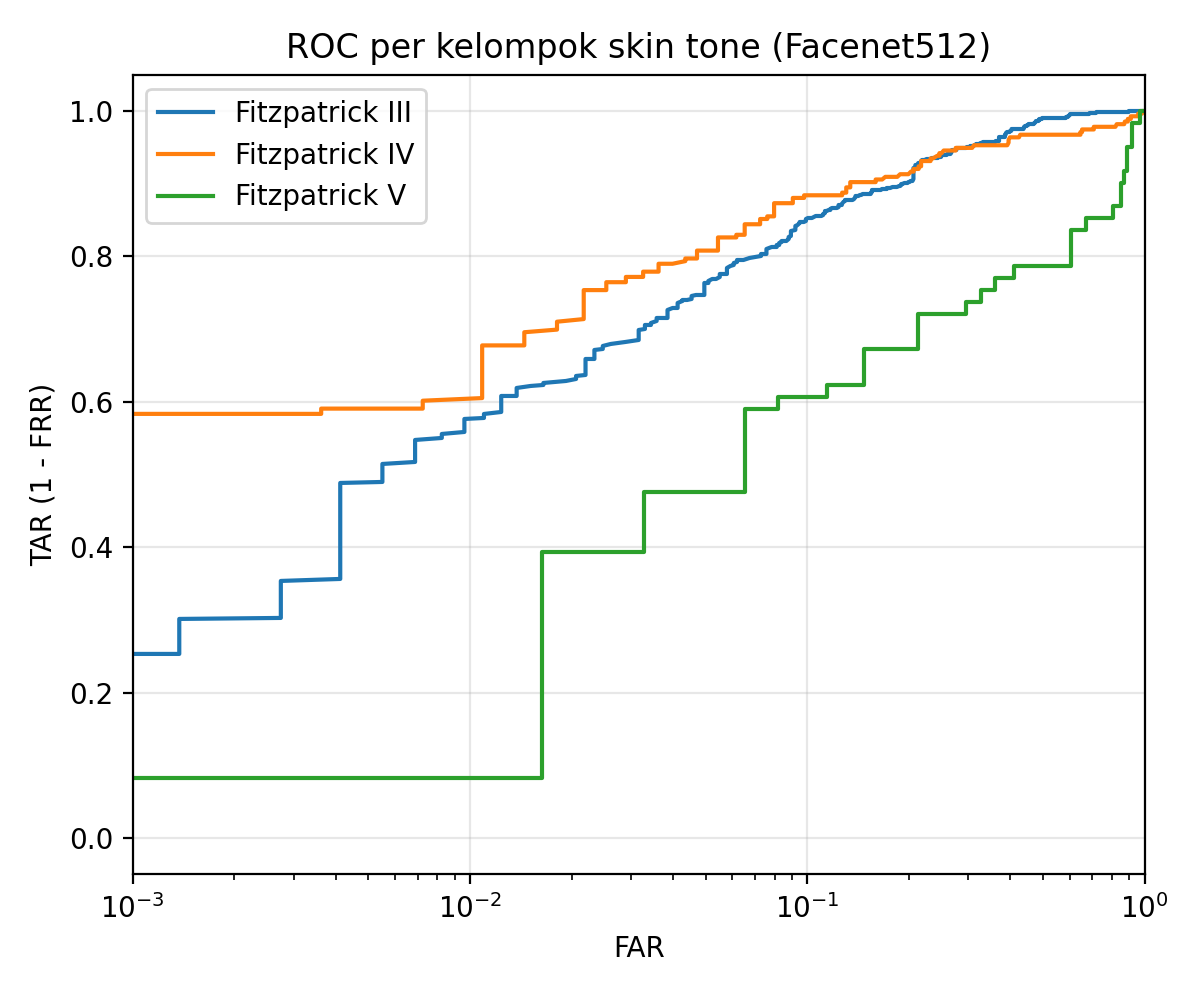

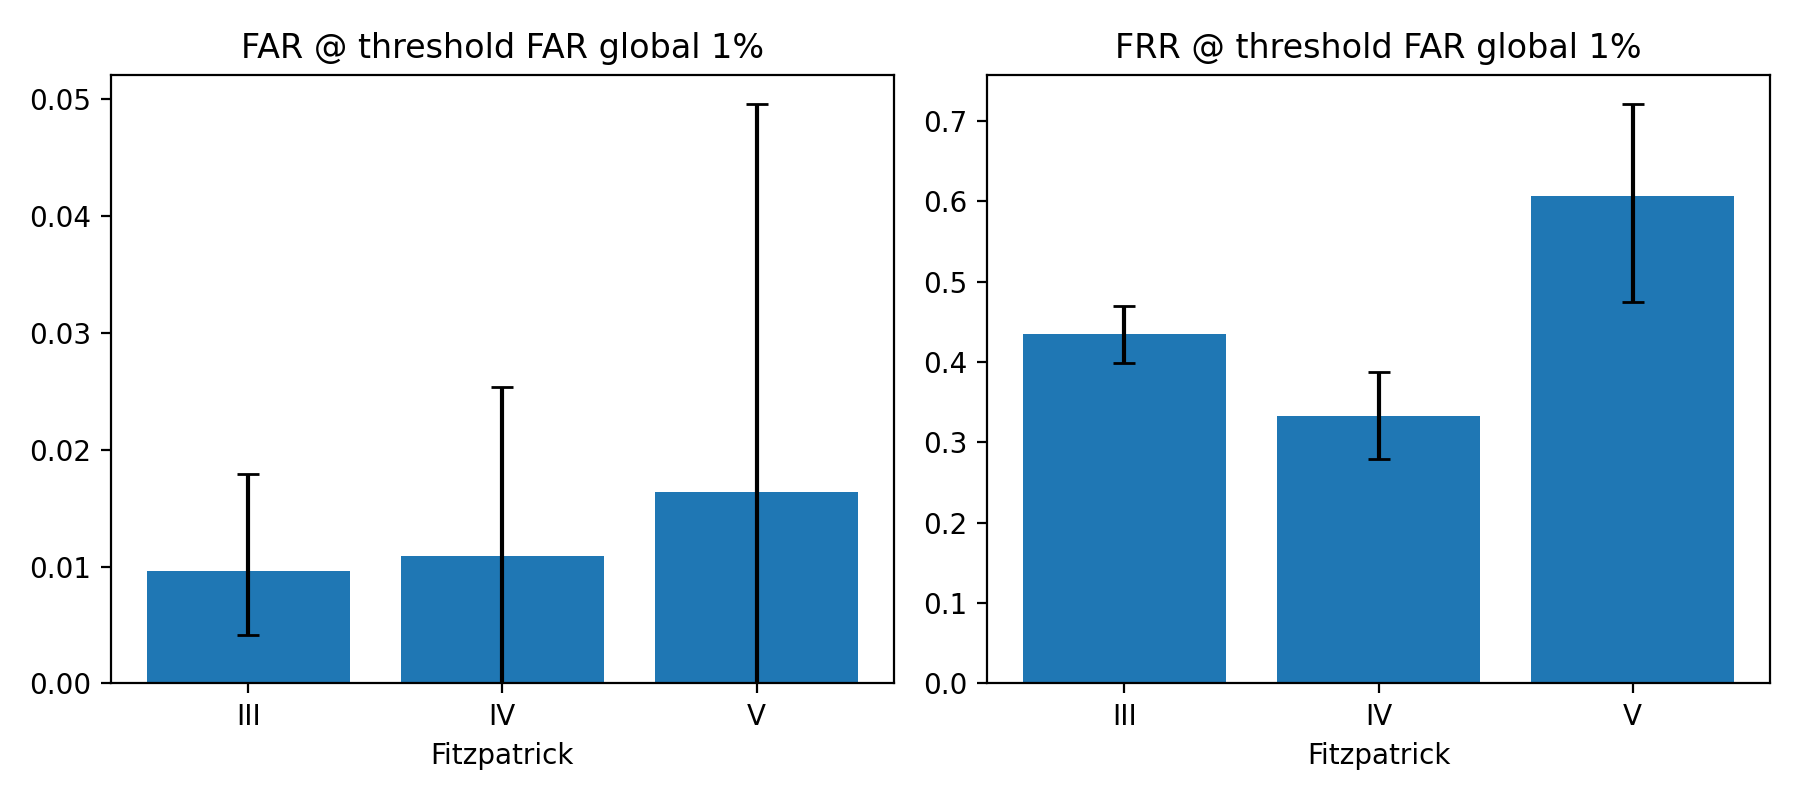

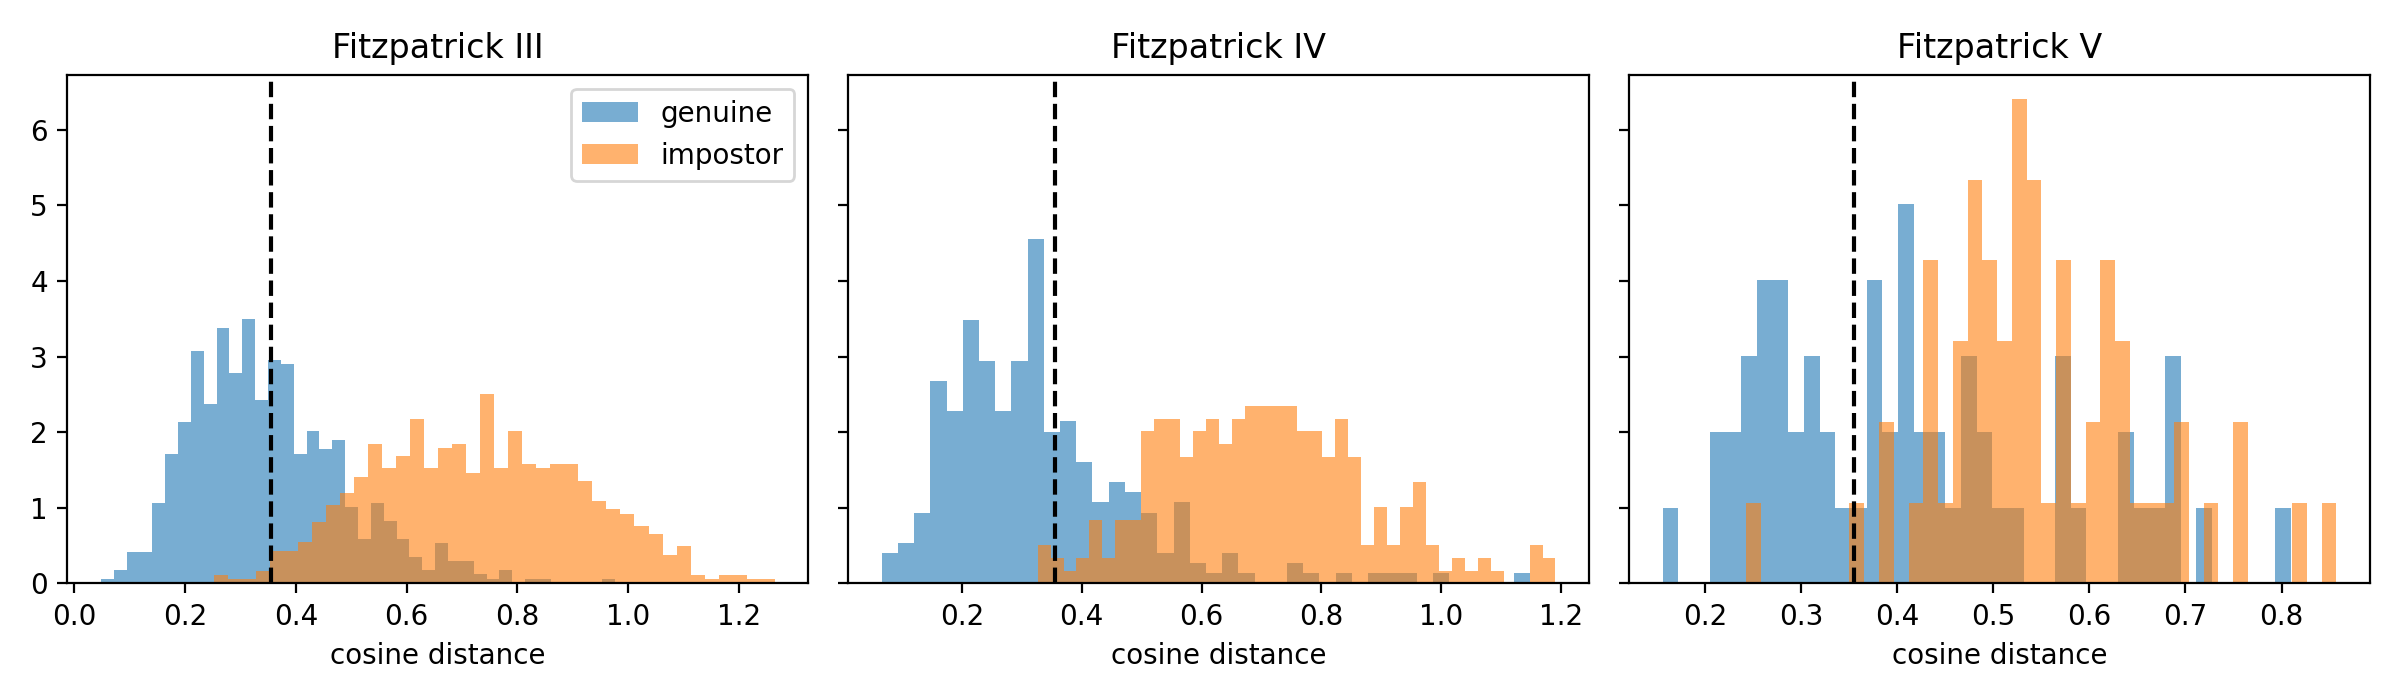

In [ ]:
import pandas as pd
from IPython.display import Image, display
for r in ["results_facenet", "results_facenet512"]:
    print("=====", r)
    display(pd.read_csv(f"{r}/fairness_summary.csv").round(4))
    display(pd.read_csv(f"{r}/metrics_skin_group_global_FAR1pct.csv").round(4))
    display(pd.read_csv(f"{r}/tests_skin_group_global_FAR1pct.csv").round(4))
    for img in ["roc_skin_group.png", "bar_far_frr.png", "dist_hist.png"]:
        display(Image(f"{r}/{img}"))

## 10. (Opsional) Analisis sensitivitas dengan label ITA
Ulangi pairs → evaluate memakai estimasi warna kulit objektif (ITA) sebagai pengganti label manual.
Jika pola bias konsisten, kesimpulan jurnal lebih kuat.

In [ ]:
!python fairness_pipeline.py pairs --meta meta_crops.csv --id-annot identities_annot.csv --img-annot images_annot.csv --out pairs_ita.csv --skin-col fitzpatrick_ita
!python fairness_pipeline.py evaluate --pairs pairs_ita.csv --emb emb_facenet512.pkl --model Facenet512 --outdir results_facenet512_ita
# Catatan: embed tidak perlu diulang jika gambar yang dipakai sama; jika ada gambar baru yang tidak ada di emb_*.pkl,
# jalankan ulang tahap embed dengan --pairs pairs_ita.csv.

python3: can't open file '/content/fairness_pipeline.py': [Errno 2] No such file or directory
python3: can't open file '/content/fairness_pipeline.py': [Errno 2] No such file or directory


In [ ]:
# 1. Pastikan Google Drive ter-mount
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# 2. Instal ulang pustaka yang diperlukan agar tidak error ModuleNotFound
!pip -q install deepface tf-keras mtcnn scikit-image scipy tqdm kagglehub

# 3. Masuk ke direktori proyek yang benar
import os
work_dir = "/content/drive/MyDrive/TA_Fairness_FaceNet"
if os.path.exists(work_dir):
    %cd {work_dir}
else:
    parent = "/content/drive/MyDrive"
    candidates = [os.path.join(parent, d) for d in os.listdir(parent) if "TA_Fairness" in d or "FaceNet" in d]
    if candidates:
        %cd {candidates[0]}
        print(f"Berpindah otomatis ke: {candidates[0]}")
    else:
        raise FileNotFoundError("Folder proyek 'TA_Fairness_FaceNet' tidak ditemukan di Drive Anda.")

# 4. Jalankan kembali ekstraksi embedding
!python fairness_pipeline.py embed --pairs pairs_ita.csv --model Facenet512 --out emb_facenet512_ita.pkl

# 5. Jalankan evaluasi dengan file embedding baru tersebut
!python fairness_pipeline.py evaluate --pairs pairs_ita.csv --emb emb_facenet512_ita.pkl --model Facenet512 --outdir results_facenet512_ita

Mounted at /content/drive
/content/drive/MyDrive/TA_Fairness_FaceNet
26-11-12 10:11:01 - Directory /root/.deepface has been created
26-11-12 10:11:01 - Directory /root/.deepface/weights has been created
embed Facenet512:   0% 0/345 [00:00<?, ?it/s]26-11-12 10:11:06 - 🔗 facenet512_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facenet512_weights.h5 to /root/.deepface/weights/facenet512_weights.h5...
Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facenet512_weights.h5
To: /root/.deepface/weights/facenet512_weights.h5

  0% 0.00/95.0M [00:00<?, ?B/s]
 12% 11.0M/95.0M [00:00<00:00, 86.2MB/s]
 26% 24.6M/95.0M [00:00<00:00, 112MB/s] 
 40% 37.7M/95.0M [00:00<00:00, 120MB/s]
 53% 50.3M/95.0M [00:00<00:00, 119MB/s]
 66% 62.9M/95.0M [00:00<00:00, 113MB/s]
 78% 74.4M/95.0M [00:00<00:00, 108MB/s]
100% 95.0M/95.0M [00:00<00:00, 109MB/s]
embed Facenet512: 100% 345/345 [03:41<00:00,  1.56it/s]
345 embeddin

## 11. Unduh semua hasil (zip)

In [ ]:
!zip -rq hasil_penelitian.zip results_* pairs*.csv meta_crops.csv identities_annot.csv images_annot.csv
from google.colab import files
files.download("hasil_penelitian.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>